# Energy Consumption Prediction

## End-to-End Machine Learning Regression Project

---

## 1. Notebook Introduction

**Project Title:** Energy Consumption Prediction using Regression Models

**Problem Statement:**  
Accurate prediction of energy consumption is crucial for efficient energy management, cost reduction, and environmental sustainability. This project aims to forecast the energy usage of a building based on environmental and temporal factors, using a real-world dataset.

**Dataset Description:**  
The dataset contains sensor readings (temperature, humidity, pressure, wind speed, etc.) along with a timestamp and the target variable: `Energy Consumption` (energy consumption of appliances in Watt-hours). The data was collected at 10-minute intervals from a low-energy house.

**Business/Real-World Importance:**  
- Enables smart grid optimization and demand-response strategies.  
- Helps building managers reduce energy waste and lower electricity bills.  
- Supports predictive maintenance and anomaly detection in HVAC systems.  
- Contributes to carbon footprint reduction by improving energy efficiency.

**Machine Learning Objective:**  
To build a regression model that predicts `Energy Consumption` energy consumption based on the given features. We will train and compare four different models (Linear Regression, Random Forest, XGBoost, Gradient Boosting) and select the best one using multiple evaluation metrics.

**Project Workflow:**  
Data Collection → Data Understanding → Data Cleaning → EDA → Feature Engineering → Preprocessing → Train/Test Split → Model Training → Model Evaluation → Model Comparison → Best Model → Conclusion




## Import Libraries

In [1]:
## 2. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

# Consistent random state
RANDOM_STATE = 42

## Load the Dataset

In [2]:
# load the data
df = pd.read_csv('/kaggle/input/datasets/mrsimple07/energy-consumption-prediction/Energy_consumption.csv')
df.head()

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
0,2022-01-01 00:00:00,25.139433,43.431581,1565.693999,5,On,Off,2.774699,Monday,No,75.364373
1,2022-01-01 01:00:00,27.731651,54.225919,1411.064918,1,On,On,21.831384,Saturday,No,83.401855
2,2022-01-01 02:00:00,28.704277,58.907658,1755.715009,2,Off,Off,6.764672,Sunday,No,78.270888
3,2022-01-01 03:00:00,20.080469,50.371637,1452.316318,1,Off,On,8.623447,Wednesday,No,56.519850
4,2022-01-01 04:00:00,23.097359,51.401421,1094.130359,9,On,Off,3.071969,Friday,No,70.811732


In [3]:
df.tail()

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
995,2022-02-11 11:00:00,28.619382,48.850160,1080.087000,5,Off,Off,21.194696,Saturday,No,82.306692
996,2022-02-11 12:00:00,23.836647,47.256435,1705.235156,4,Off,On,25.748176,Tuesday,Yes,66.577320
997,2022-02-11 13:00:00,23.005340,48.720501,1320.285281,6,Off,On,0.297079,Friday,Yes,72.753471
998,2022-02-11 14:00:00,25.138365,31.306459,1309.079719,3,On,Off,20.425163,Thursday,Yes,76.950389
999,2022-02-11 15:00:00,23.051165,42.615421,1018.140606,6,Off,On,2.455657,Saturday,No,71.545311


In [4]:
df.shape

(1000, 11)

In [5]:
df.columns.tolist()

['Timestamp',
 'Temperature',
 'Humidity',
 'SquareFootage',
 'Occupancy',
 'HVACUsage',
 'LightingUsage',
 'RenewableEnergy',
 'DayOfWeek',
 'Holiday',
 'EnergyConsumption']

## Dataset Understanding

In [6]:
# Basic Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          1000 non-null   object 
 1   Temperature        1000 non-null   float64
 2   Humidity           1000 non-null   float64
 3   SquareFootage      1000 non-null   float64
 4   Occupancy          1000 non-null   int64  
 5   HVACUsage          1000 non-null   object 
 6   LightingUsage      1000 non-null   object 
 7   RenewableEnergy    1000 non-null   float64
 8   DayOfWeek          1000 non-null   object 
 9   Holiday            1000 non-null   object 
 10  EnergyConsumption  1000 non-null   float64
dtypes: float64(5), int64(1), object(5)
memory usage: 86.1+ KB


In [7]:
# Statistical Summary
df.describe(include='all')

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
count,1000,1000.000000,1000.000000,1000.000000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000
unique,1000,NaN,NaN,NaN,NaN,2,2,NaN,7,2,NaN
top,2022-02-11 15:00:00,NaN,NaN,NaN,NaN,Off,Off,NaN,Friday,No,NaN
freq,1,NaN,NaN,NaN,NaN,508,509,NaN,164,533,NaN
mean,NaN,24.982026,45.395412,1500.052488,4.581000,NaN,NaN,15.132813,NaN,NaN,77.055873
std,NaN,2.836850,8.518905,288.418873,2.865598,NaN,NaN,8.745917,NaN,NaN,8.144112
min,NaN,20.007565,30.015975,1000.512661,0.000000,NaN,NaN,0.006642,NaN,NaN,53.263278
25%,NaN,22.645070,38.297722,1247.108548,2.000000,NaN,NaN,7.628385,NaN,NaN,71.544690
50%,NaN,24.751637,45.972116,1507.967426,5.000000,NaN,NaN,15.072296,NaN,NaN,76.943696
75%,NaN,27.418174,52.420066,1740.340165,7.000000,NaN,NaN,22.884064,NaN,NaN,82.921742


In [8]:
# Data Types
df.dtypes

Timestamp             object
Temperature          float64
Humidity             float64
SquareFootage        float64
Occupancy              int64
HVACUsage             object
LightingUsage         object
RenewableEnergy      float64
DayOfWeek             object
Holiday               object
EnergyConsumption    float64
dtype: object

In [9]:
# Unique Values per Feature
df.nunique().sort_values()

LightingUsage           2
HVACUsage               2
Holiday                 2
DayOfWeek               7
Occupancy              10
Humidity             1000
SquareFootage        1000
Timestamp            1000
RenewableEnergy      1000
Temperature          1000
EnergyConsumption    1000
dtype: int64

## Data Quality Analysis

In [10]:
# Missing Values
df.isnull().sum()

Timestamp            0
Temperature          0
Humidity             0
SquareFootage        0
Occupancy            0
HVACUsage            0
LightingUsage        0
RenewableEnergy      0
DayOfWeek            0
Holiday              0
EnergyConsumption    0
dtype: int64

In [11]:
# Duplicate Rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Timestamp          1000 non-null   object 
 1   Temperature        1000 non-null   float64
 2   Humidity           1000 non-null   float64
 3   SquareFootage      1000 non-null   float64
 4   Occupancy          1000 non-null   int64  
 5   HVACUsage          1000 non-null   object 
 6   LightingUsage      1000 non-null   object 
 7   RenewableEnergy    1000 non-null   float64
 8   DayOfWeek          1000 non-null   object 
 9   Holiday            1000 non-null   object 
 10  EnergyConsumption  1000 non-null   float64
dtypes: float64(5), int64(1), object(5)
memory usage: 86.1+ KB


In [13]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

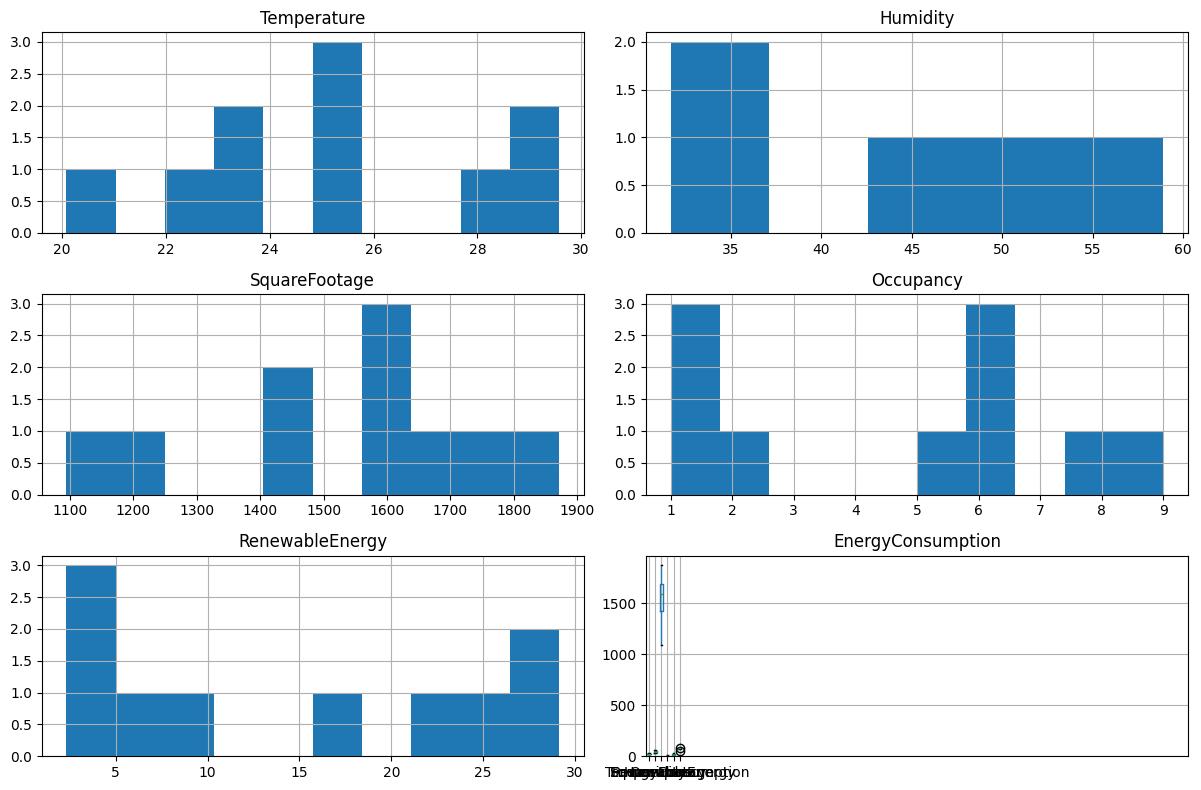

In [14]:
# Numerical Feature Analysis
# We select all numerical columns except the target and identifiers.

numerical_features = [feature for feature in df.columns if feature not in ['Timestamp', 'HVACUsage', 'LightingUsage', 'Holiday', 'DayOfWeek']]

# Plot histograms and box plots for a subset of numerical features
subset = df[numerical_features].head(10)
subset.hist(figsize=(12, 8))
subset.boxplot(figsize=(12, 8))
plt.tight_layout()
plt.show()


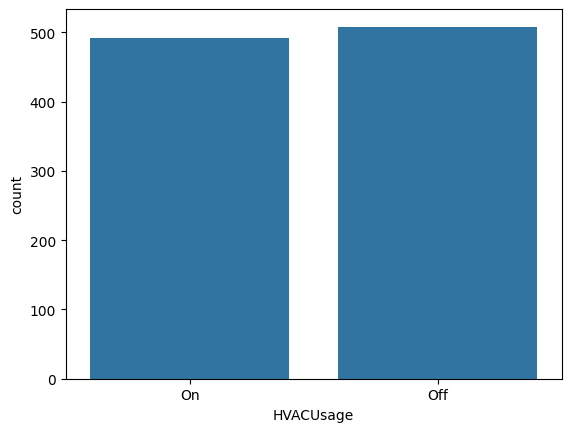

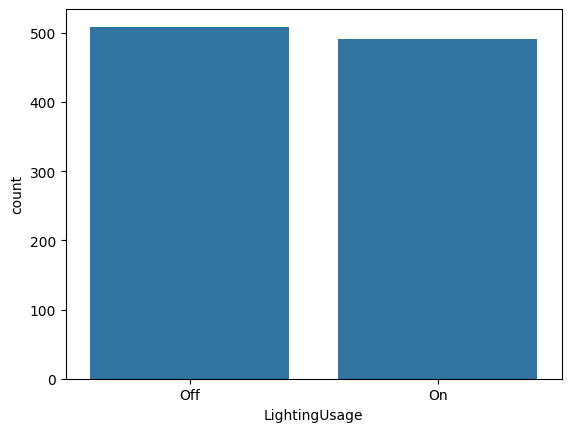

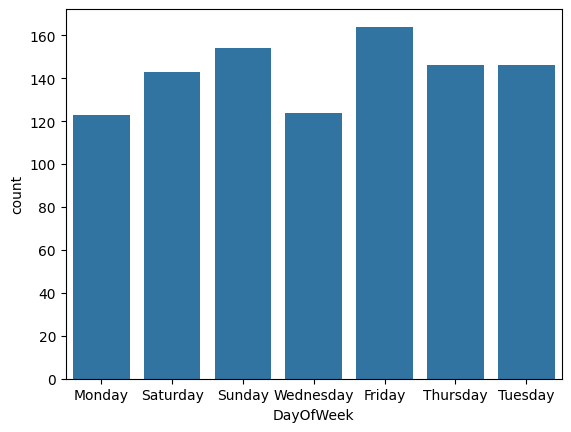

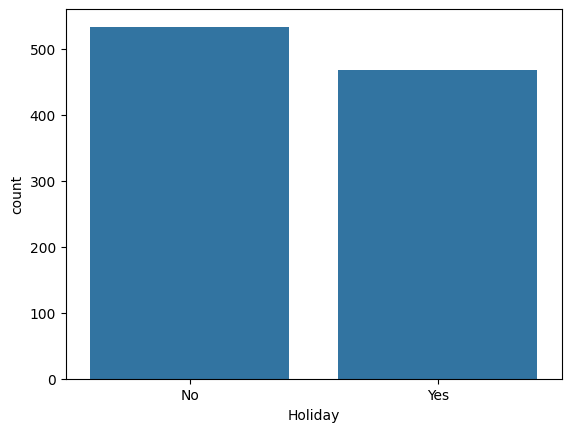

In [15]:
# select only categorical features
cat_col = df.select_dtypes(include=['object']).columns

# make count plot for each categorical feature
for col in cat_col:
    sns.countplot(data=df, x=col)
    plt.show()

## Outlier Analysis

In [16]:
Q1 = df[numerical_features].quantile(0.25)
Q3 = df[numerical_features].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = ((df[numerical_features] < (Q1 - 1.5 * IQR)) | (df[numerical_features] > (Q3 + 1.5 * IQR)))
outlier_counts = outlier_mask.sum()
print("Number of outliers per feature:")
print(outlier_counts[outlier_counts > 0])

Number of outliers per feature:
EnergyConsumption    1
dtype: int64


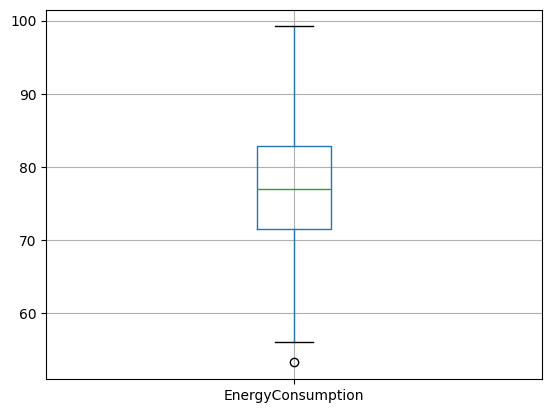

In [17]:
# box plot for energy consumption
df.boxplot(column='EnergyConsumption')
plt.show()

## Correlation Analysis

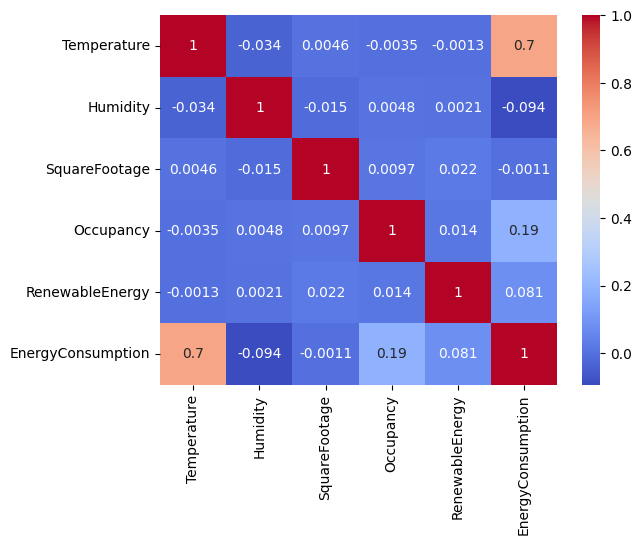

In [18]:
# heatmap for correlation matrix of numerical features
corr_matrix = df[numerical_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

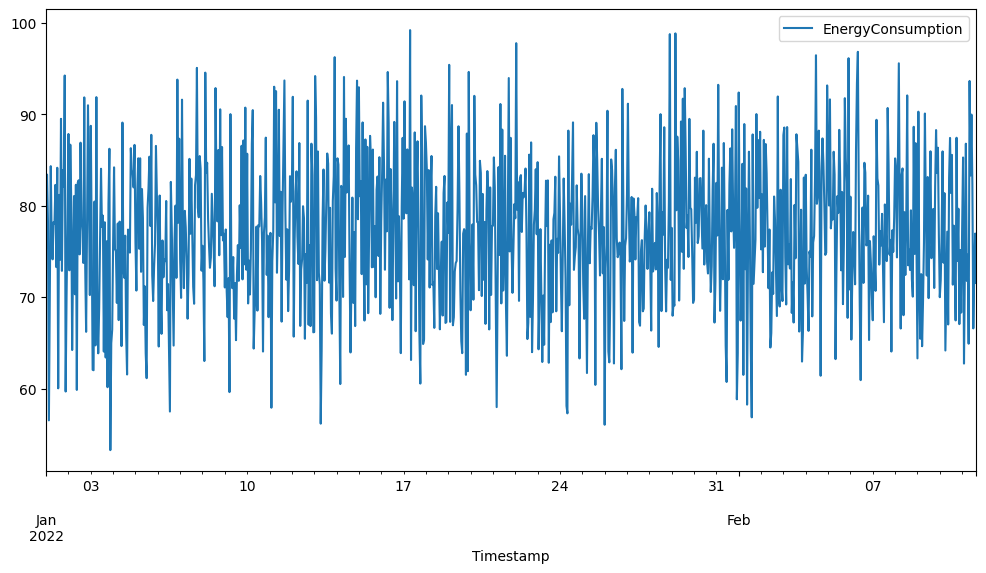

In [19]:
# time series plot for energy consumption more detials
df.plot(x='Timestamp', y='EnergyConsumption', figsize=(12, 6))
plt.show()

In [20]:
encoder = LabelEncoder()
df['DayOfWeek'] = encoder.fit_transform(df['DayOfWeek'])
df['Holiday'] = encoder.fit_transform(df['Holiday'])
df['LightingUsage'] = encoder.fit_transform(df['LightingUsage'])
df['HVACUsage'] = encoder.fit_transform(df['HVACUsage'])

# check the result
df.head()

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
0,2022-01-01 00:00:00,25.139433,43.431581,1565.693999,5,1,0,2.774699,1,0,75.364373
1,2022-01-01 01:00:00,27.731651,54.225919,1411.064918,1,1,1,21.831384,2,0,83.401855
2,2022-01-01 02:00:00,28.704277,58.907658,1755.715009,2,0,0,6.764672,3,0,78.270888
3,2022-01-01 03:00:00,20.080469,50.371637,1452.316318,1,0,1,8.623447,6,0,56.519850
4,2022-01-01 04:00:00,23.097359,51.401421,1094.130359,9,1,0,3.071969,0,0,70.811732


In [21]:
scaler = StandardScaler()
df[numerical_features] = scaler.fit_transform(df[numerical_features])
df.head()

,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption
0,2022-01-01 00:00:00,0.055514,-0.230642,0.227705,0.146290,1,0,-1.413722,1,0,-0.207800
1,2022-01-01 01:00:00,0.969738,1.037096,-0.308690,-1.250277,1,1,0.766292,2,0,0.779601
2,2022-01-01 02:00:00,1.312764,1.586942,0.886871,-0.901135,0,0,-0.957284,3,0,0.149264
3,2022-01-01 03:00:00,-1.728681,0.584431,-0.165593,-1.250277,0,1,-0.744647,6,0,-2.522841
4,2022-01-01 04:00:00,-0.664684,0.705374,-1.408109,1.542858,1,0,-1.379716,0,0,-0.767090


In [22]:
# split the data into training and testing sets
# drop Timeestamp and EnergyConsumption
X = df.drop(['Timestamp', 'EnergyConsumption'], axis=1)
y = df['EnergyConsumption']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# check the shape of the data
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 9)
(200, 9)
(800,)
(200,)


Performance Metrics Table:
                    Model      MAE      MSE       R2
         LinearRegression 0.504735 0.397558 0.597827
    RandomForestRegressor 0.542437 0.458018 0.536665
GradientBoostingRegressor 0.553296 0.476474 0.517995
             XGBRegressor 0.576094 0.520858 0.473096

Generating plots...


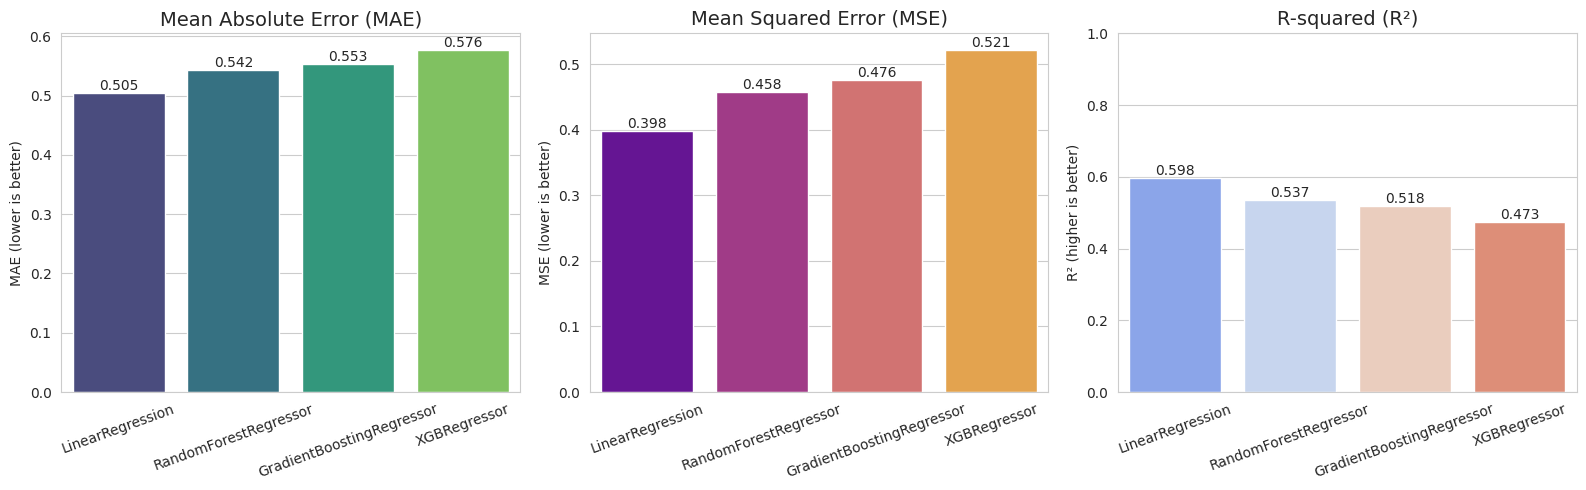

In [23]:
# 1. Define models
models = {
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(),
    'XGBRegressor': XGBRegressor(),
    'GradientBoostingRegressor': GradientBoostingRegressor()
}

# 2. Train and evaluate
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'R2': r2
    })

# Convert to DataFrame
df_results = pd.DataFrame(results)

# Sort by MAE (best first) for consistent color order
df_results = df_results.sort_values(by='MAE', ascending=True)

print("Performance Metrics Table:")
print(df_results.to_string(index=False))
print("\nGenerating plots...")

# --------------------------------------------------------------
# 3. Create comparison plots
# --------------------------------------------------------------
sns.set_style('whitegrid')
plt.figure(figsize=(16, 5))  # Wide figure for 3 subplots

# --- Subplot 1: MAE ---
plt.subplot(1, 3, 1)
ax1 = sns.barplot(data=df_results, x='Model', y='MAE', palette='viridis')
plt.title('Mean Absolute Error (MAE)', fontsize=14)
plt.ylabel('MAE (lower is better)')
plt.xlabel('')
plt.xticks(rotation=20)

# Add values on top of bars
for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.3f}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10)

# --- Subplot 2: MSE ---
plt.subplot(1, 3, 2)
ax2 = sns.barplot(data=df_results, x='Model', y='MSE', palette='plasma')
plt.title('Mean Squared Error (MSE)', fontsize=14)
plt.ylabel('MSE (lower is better)')
plt.xlabel('')
plt.xticks(rotation=20)

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.3f}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10)

# --- Subplot 3: R² ---
plt.subplot(1, 3, 3)
ax3 = sns.barplot(data=df_results, x='Model', y='R2', palette='coolwarm')
plt.title('R-squared (R²)', fontsize=14)
plt.ylabel('R² (higher is better)')
plt.xlabel('')
plt.ylim(0, 1)  # R² usually between 0 and 1 for good models; adjust if negative
plt.xticks(rotation=20)

for p in ax3.patches:
    ax3.annotate(f'{p.get_height():.3f}', 
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## Conclusion 
According to this data set Linear Regression best model

# Thank you for reading our notebook if you have any questions or suggestions, please comment. :)